In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.geometry import box

import matplotlib.pyplot as plt

# Load shapefiles

In [2]:
# load Naturraeume Brandenburg
NATRAUM = gpd.read_file("../data/brandenburg_shape/naturraum_scholz_ohne_Berlin.gpkg", layer="naturraum_scholz_ohne_berlin")
BER_SHAPE = gpd.read_file("../data/brandenburg_shape/pos_1/GRENZE_184201-5683624_ortsteile.gpkg", layer="berlinflaeche_0")

In [3]:
print(NATRAUM.crs)
print(NATRAUM.geom_type.value_counts().to_dict())
print(len(NATRAUM))
print(NATRAUM.total_bounds)

EPSG:4326
{'MultiPolygon': 79}
79
[11.26601236 51.35826207 14.76432439 53.55806679]


<Axes: >

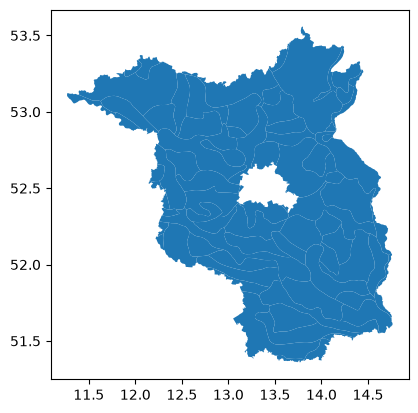

In [4]:
NATRAUM.plot()

In [4]:
naturraum_3035 = NATRAUM.to_crs("EPSG:3035")
berlin_3035 = BER_SHAPE.to_crs("EPSG:3035")

# Load imported data

In [5]:
# load imported data
data_dir = Path("../data/imported")
list(data_dir.glob("*.nc"))

[WindowsPath('../data/imported/grids_germany_daily_soil_moisture_composite_0-10_v1.nc'),
 WindowsPath('../data/imported/grids_germany_daily_soil_moisture_composite_190-200_v1.nc'),
 WindowsPath('../data/imported/grids_germany_daily_soil_moisture_composite_90-100_v1.nc'),
 WindowsPath('../data/imported/hyras_pr_v6-1_2001_2025.nc'),
 WindowsPath('../data/imported/hyras_tasmax_v6-1_2001_2025.nc'),
 WindowsPath('../data/imported/hyras_tasmin_v6-1_2001_2025.nc'),
 WindowsPath('../data/imported/hyras_tas_v6-1_2001_2025.nc')]

In [6]:
pr = xr.open_dataset(data_dir/"hyras_pr_v6-1_2001_2025.nc")
tas = xr.open_dataset(data_dir/"hyras_tas_v6-1_2001_2025.nc")
tasmax = xr.open_dataset(data_dir/"hyras_tasmax_v6-1_2001_2025.nc")
tasmin = xr.open_dataset(data_dir/"hyras_tasmin_v6-1_2001_2025.nc")
sm_top = xr.open_dataset(data_dir/"grids_germany_daily_soil_moisture_composite_0-10_v1.nc")
sm_mid = xr.open_dataset(data_dir/"grids_germany_daily_soil_moisture_composite_90-100_v1.nc")
sm_low = xr.open_dataset(data_dir/"grids_germany_daily_soil_moisture_composite_190-200_v1.nc")

In [12]:
print(pr.dims)
print(tas.dims)
print(tasmax.dims)
print(tasmin.dims)
print(sm_top.dims)
print(sm_mid.dims)
print(sm_low.dims)

FrozenMappingWarningOnValuesAccess({'time': 9131, 'y': 265, 'x': 265})
FrozenMappingWarningOnValuesAccess({'time': 9131, 'y': 265, 'x': 265})
FrozenMappingWarningOnValuesAccess({'time': 9131, 'y': 265, 'x': 265})
FrozenMappingWarningOnValuesAccess({'time': 9131, 'y': 265, 'x': 265})
FrozenMappingWarningOnValuesAccess({'time': 9131, 'y': 269, 'x': 270})
FrozenMappingWarningOnValuesAccess({'time': 9131, 'y': 269, 'x': 270})
FrozenMappingWarningOnValuesAccess({'time': 9131, 'y': 269, 'x': 270})


In [13]:
print(pr.var)
print(tas.var)
print(tasmax.var)
print(tasmin.var)
print(sm_top.var)
print(sm_mid.var)
print(sm_low.var)

<bound method DatasetAggregations.var of <xarray.Dataset> Size: 3GB
Dimensions:  (time: 9131, y: 265, x: 265)
Coordinates:
  * time     (time) datetime64[ns] 73kB 2001-01-01 2001-01-02 ... 2025-12-31
  * y        (y) float64 2kB 3.136e+06 3.136e+06 3.138e+06 ... 3.398e+06 3.4e+06
  * x        (x) float64 2kB 4.396e+06 4.398e+06 4.398e+06 ... 4.66e+06 4.66e+06
    lat      (y, x) float64 562kB ...
    lon      (y, x) float64 562kB ...
Data variables:
    pr       (time, y, x) float32 3GB ...>
<bound method DatasetAggregations.var of <xarray.Dataset> Size: 5GB
Dimensions:  (time: 9131, y: 265, x: 265)
Coordinates:
  * time     (time) datetime64[ns] 73kB 2001-01-01 2001-01-02 ... 2025-12-31
  * y        (y) float64 2kB 3.136e+06 3.136e+06 3.138e+06 ... 3.398e+06 3.4e+06
  * x        (x) float64 2kB 4.396e+06 4.398e+06 4.398e+06 ... 4.66e+06 4.66e+06
    lon      (y, x) float64 562kB ...
    lat      (y, x) float64 562kB ...
Data variables:
    tas      (time, y, x) float64 5GB ...>
<bound

# Summary Statistics

In [7]:
# extract data arrays
pr_da = pr["pr"]
tas_da = tas["tas"]
tasmax_da = tasmax["tasmax"]
tasmin_da = tasmin["tasmin"]
sm_top_da = sm_top["sm_dwd_0_10"]
sm_mid_da = sm_mid["sm_dwd_90_100"]
sm_low_da = sm_low["sm_dwd_190_200"]

In [ ]:
## Code for this summary table by ChatGPT
summary = []

variables = [
    ("Precipitation", pr_da),
    ("Mean temperature", tas_da),
    ("Maximum temperature", tasmax_da),
    ("Minimum temperature", tasmin_da),
    ("Surface soil moisture", sm_top_da),
    ("Soil moisture 90–100 cm", sm_mid_da),
    ("Soil moisture 190–200 cm", sm_low_da),
]

for name, da in variables:
    
    # spatial mean for each day
    spatial_mean = da.mean(dim=[d for d in da.dims if d != "time"])
    
    summary.append({
        "Variable": name,
        "Observations": da.sizes["time"],
        "Grid cells": da.size // da.sizes["time"],
        "Mean": float(spatial_mean.mean()),
        "Std": float(spatial_mean.std()),
        "Min": float(spatial_mean.min()),
        "Max": float(spatial_mean.max())
    })

summary_df = pd.DataFrame(summary)

summary_df

,Variable,Observations,Grid cells,Mean,Std,Min,Max
0,Precipitation,9131,70225,1.603008,2.839783,0.000000,44.646229
1,Mean temperature,9131,70225,9.971562,7.496402,-16.282463,28.454485
2,Maximum temperature,9131,70225,14.468775,8.906834,-11.944492,37.618231
3,Minimum temperature,9131,70225,5.354115,6.445609,-21.035923,20.055373
4,Surface soil moisture,9131,72630,78.229520,31.165685,1.503894,148.779011
5,Soil moisture 90–100 cm,9131,72630,71.119270,24.116802,26.435982,123.975965
6,Soil moisture 190–200 cm,9131,72630,75.542260,15.097781,44.116393,118.641249


In [16]:
summary_df.to_csv("../output/tables/summary_statistics_daily_raw_variables.csv", index=False)

# Visualization

## spatial mean / temporal distribution

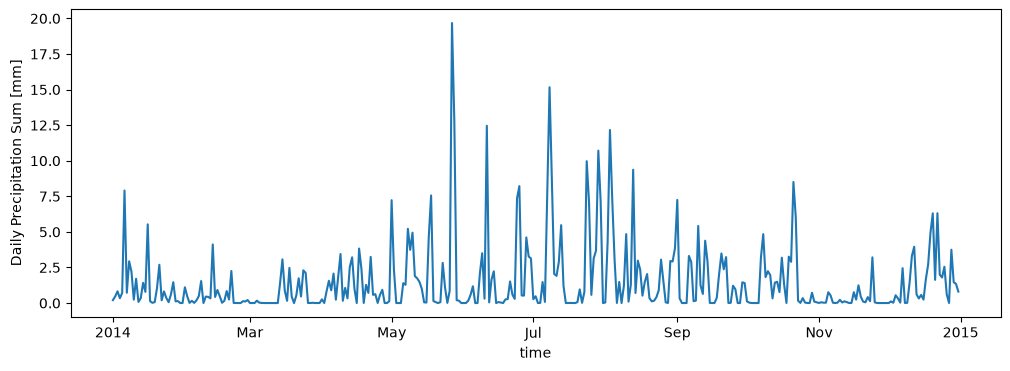

In [ ]:
# calculate mean for a year
pr_2014_mean =pr.sel(time="2014").mean(dim=["y","x"])
pr_2014_mean["pr"].plot(figsize=(12,4))

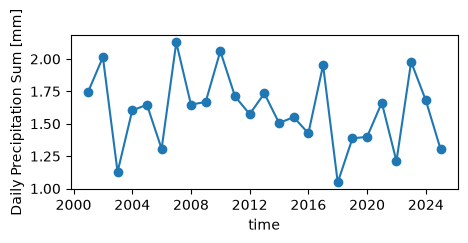

In [8]:
pr_da.mean(dim=["y", "x"]).resample(time="YS").mean().plot(marker="o", figsize=(5, 2))

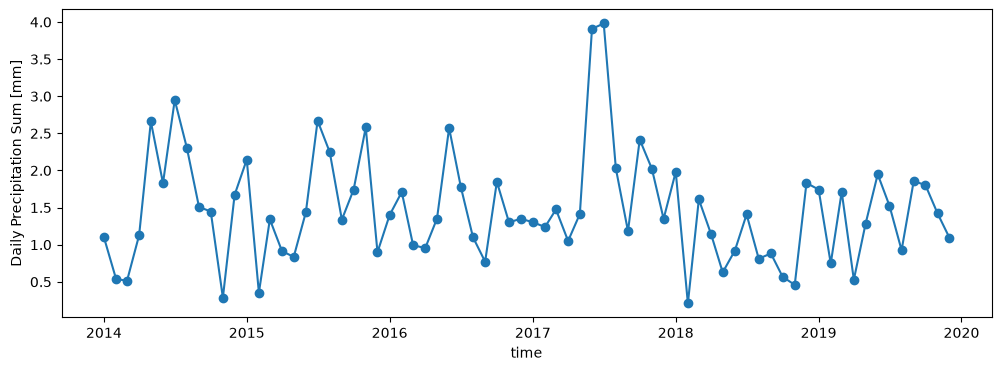

In [53]:
pr_yrl_mean = pr.mean(dim=["y","x"]).resample(time="MS").mean()
pr_yrl_mean 
pr_yrl_mean["pr"].plot(marker='o', figsize=(12,4))

In [9]:
# compare multiple years over monthly sums
pr_mean = pr_da.mean(dim=["y","x"])
pr_monthly = pr_mean.resample(time="MS").sum()

In [10]:
pr_monthly = pr_monthly.assign_coords(
    year=pr_monthly.time.dt.year,
    month=pr_monthly.time.dt.month
)

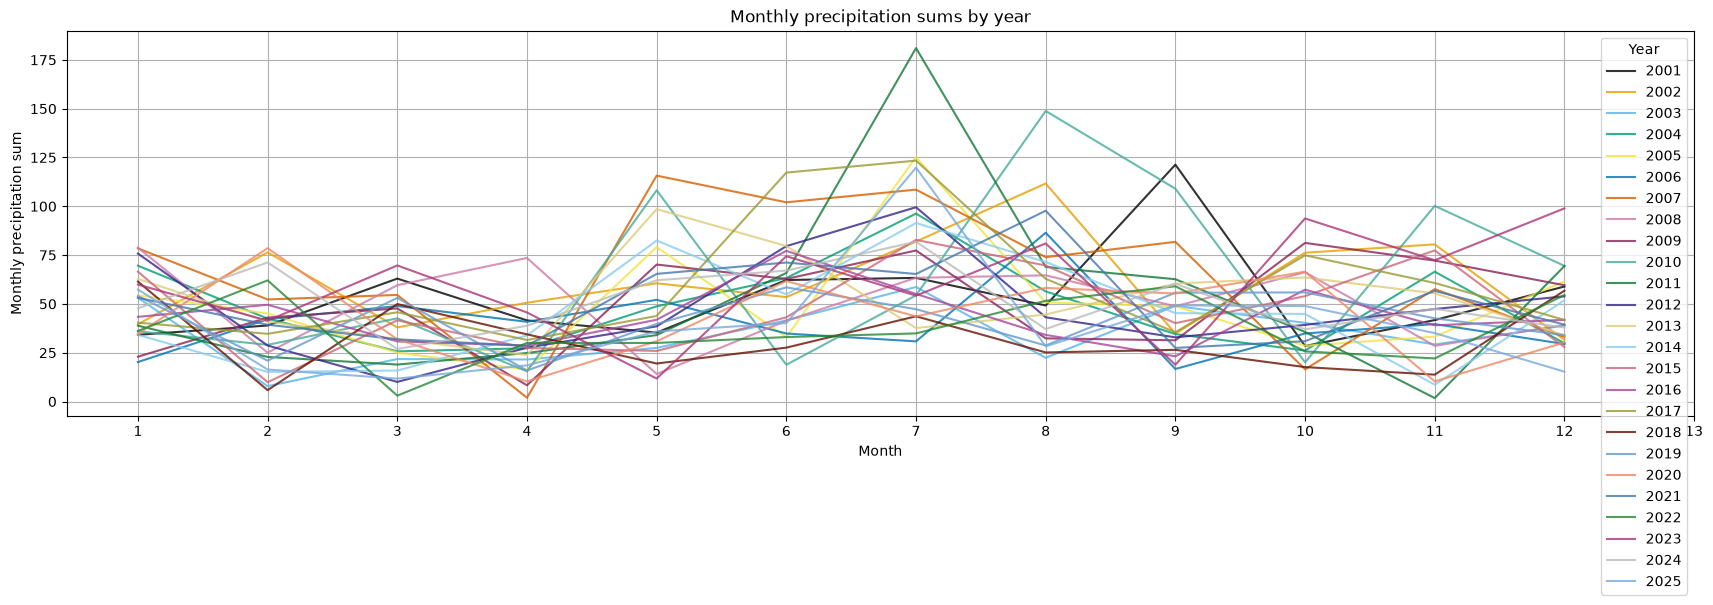

In [19]:
colors = [
    "#000000",  # black
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#009E73",  # bluish green
    "#F0E442",  # yellow
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#CC79A7",  # reddish purple
    "#882255",  # dark wine
    "#44AA99",  # teal
    "#117733",  # dark green
    "#332288",  # dark blue
    "#DDCC77",  # sand
    "#88CCEE",  # light blue
    "#CC6677",  # muted red
    "#AA4499",  # purple
    "#999933",  # olive
    "#661100",  # dark brown
    "#6699CC",  # muted blue
    "#EE8866",  # coral
    "#4477AA",  # steel blue
    "#228833",  # green
    "#AA3377",  # magenta
    "#BBBBBB",  # grey
    "#77AADD",  # light steel blue
]

fig, ax = plt.subplots(figsize=(21, 5))

for i, year in enumerate(range(2001, 2026)):
    data = pr_monthly.sel(time=str(year))
    
    ax.plot(
        data.month,
        data,
        color=colors[i],
        alpha=0.8,
        label=str(year)
    )

ax.set_xlabel("Month")
ax.set_ylabel("Monthly precipitation sum")
ax.set_title("Monthly precipitation sums by year")
ax.set_xticks(range(1, 14))
ax.legend(title="Year")
ax.grid(True)

plt.show()

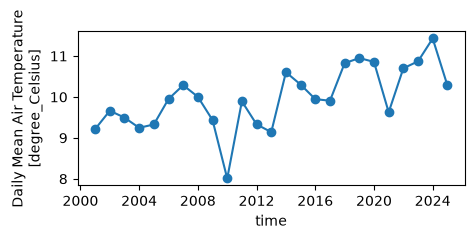

In [20]:
tas_da.mean(dim=["y", "x"]).resample(time="YS").mean().plot(marker="o", figsize=(5, 2))

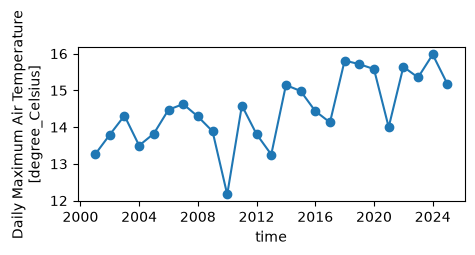

In [21]:
tasmax_da.mean(dim=["y", "x"]).resample(time="YS").mean().plot(marker="o", figsize=(5, 2))

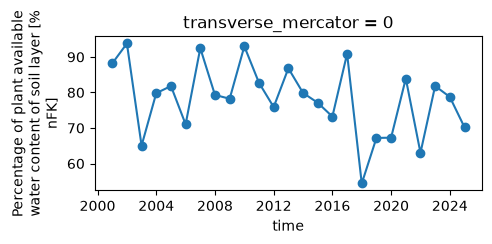

In [22]:
sm_top_da.mean(dim=["y", "x"]).resample(time="YS").mean().plot(marker="o", figsize=(5, 2))

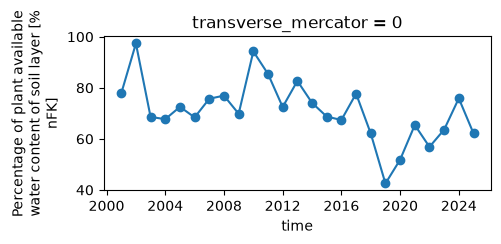

In [23]:
sm_mid_da.mean(dim=["y", "x"]).resample(time="YS").mean().plot(marker="o", figsize=(5, 2))

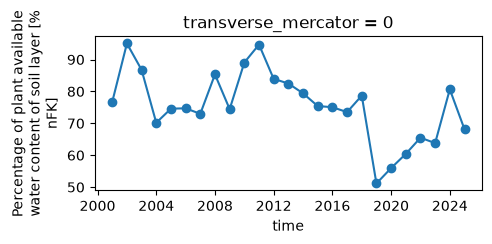

In [24]:
sm_low_da.mean(dim=["y", "x"]).resample(time="YS").mean().plot(marker="o", figsize=(5, 2))

## temporal mean / spatial distribution

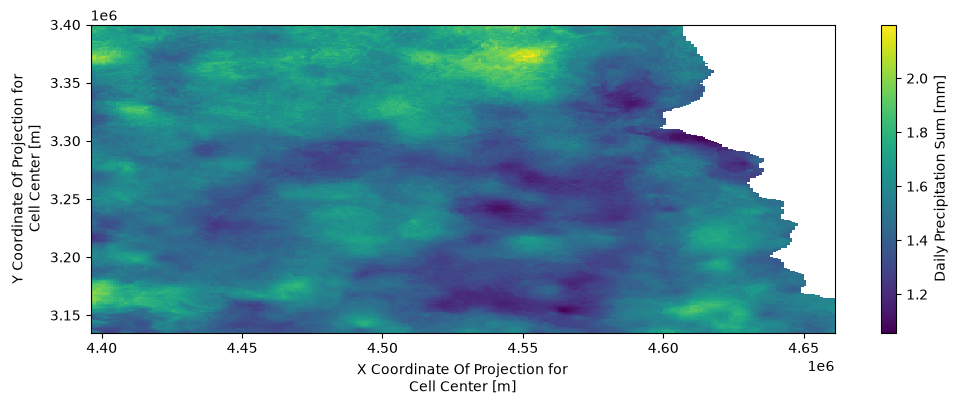

In [37]:
## temporal mean / spatial distribution
pr_2014 = pr.sel(time=slice("2014-01-01", "2014-12-31"))
pr_2014_spatial_mean = pr_2014.mean(dim="time")
pr_2014_spatial_mean["pr"].plot(figsize=(12,4))

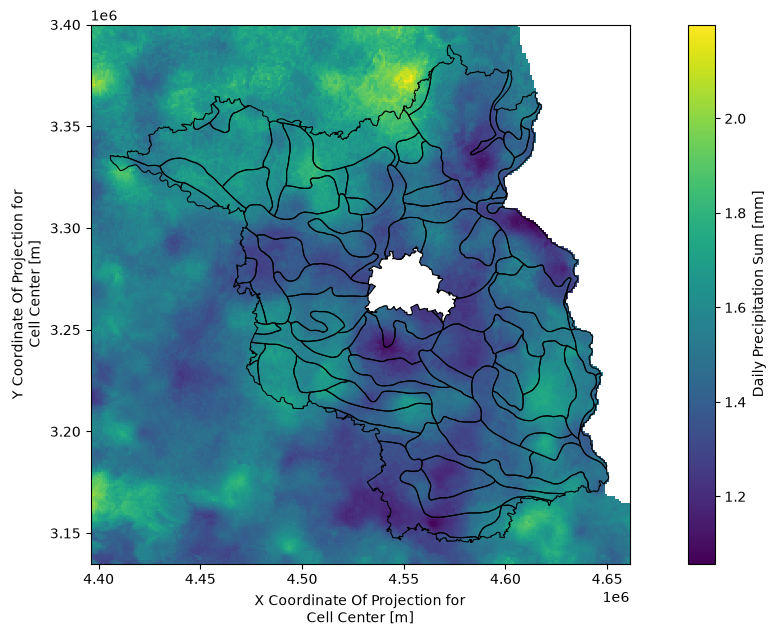

In [49]:
fig, ax = plt.subplots(figsize=(15,7))

pr_2014_spatial_mean["pr"].plot(ax=ax)

naturraum_3035.boundary.plot(ax=ax, color="black", linewidth=0.8)
berlin_3035.plot(ax=ax, facecolor="white")

ax.set_aspect("equal")

plt.show()

In [79]:
# compare all years spatially
pr_annual = pr["pr"].groupby("time.year").sum(dim="time")

In [80]:
# find overall min and max for universal legend
vmin = float(pr_annual.min())
vmax = float(pr_annual.max())

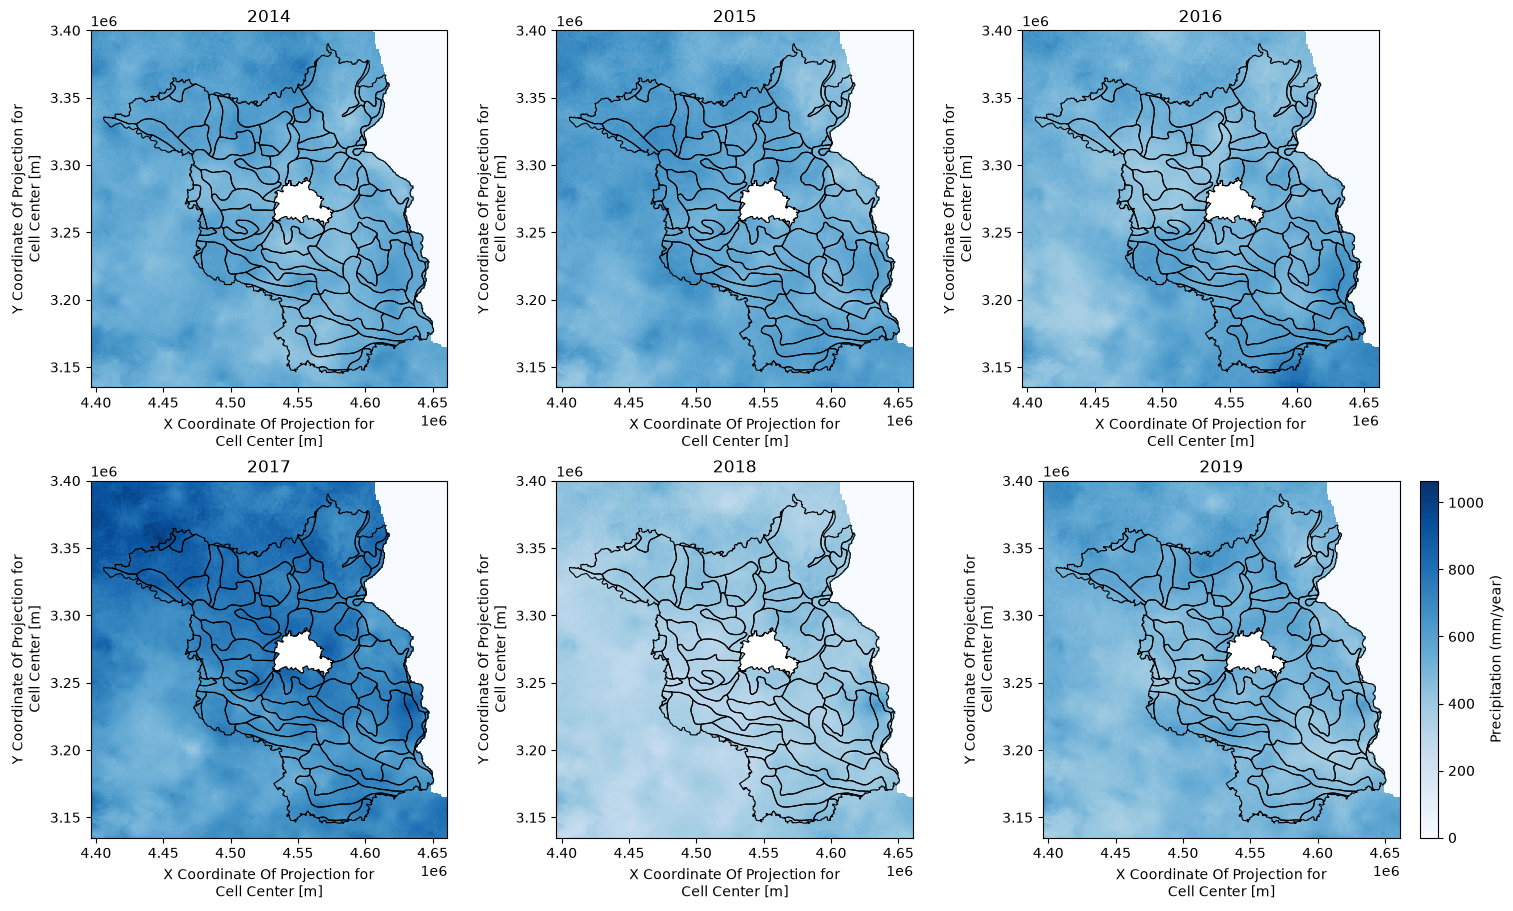

In [81]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9),
    constrained_layout=True
)

axes = axes.ravel()

for i, year in enumerate(range(2014, 2020)):
    
    pr_year = pr_annual.sel(year=year)
    
    pr_year.plot(
        ax=axes[i],
        vmin=vmin,
        vmax=vmax,
        cmap="Blues",
        add_colorbar=(i == 5),
        cbar_kwargs={
            "label": "Precipitation (mm/year)"
        } if i == 5 else None
    )
    
    naturraum_3035.boundary.plot(
        ax=axes[i],
        color="black",
        linewidth=0.8
    )
    
    berlin_3035.plot(
        ax=axes[i],
        facecolor="white"
    )
    
    axes[i].set_title(str(year))
    axes[i].set_aspect("equal")

plt.show()

In [25]:
sm_top_annual = sm_top_da.groupby("time.year").mean(dim="time")

In [26]:
sm_top_min = float(sm_top_annual.min())
sm_top_max = float(sm_top_annual.max())

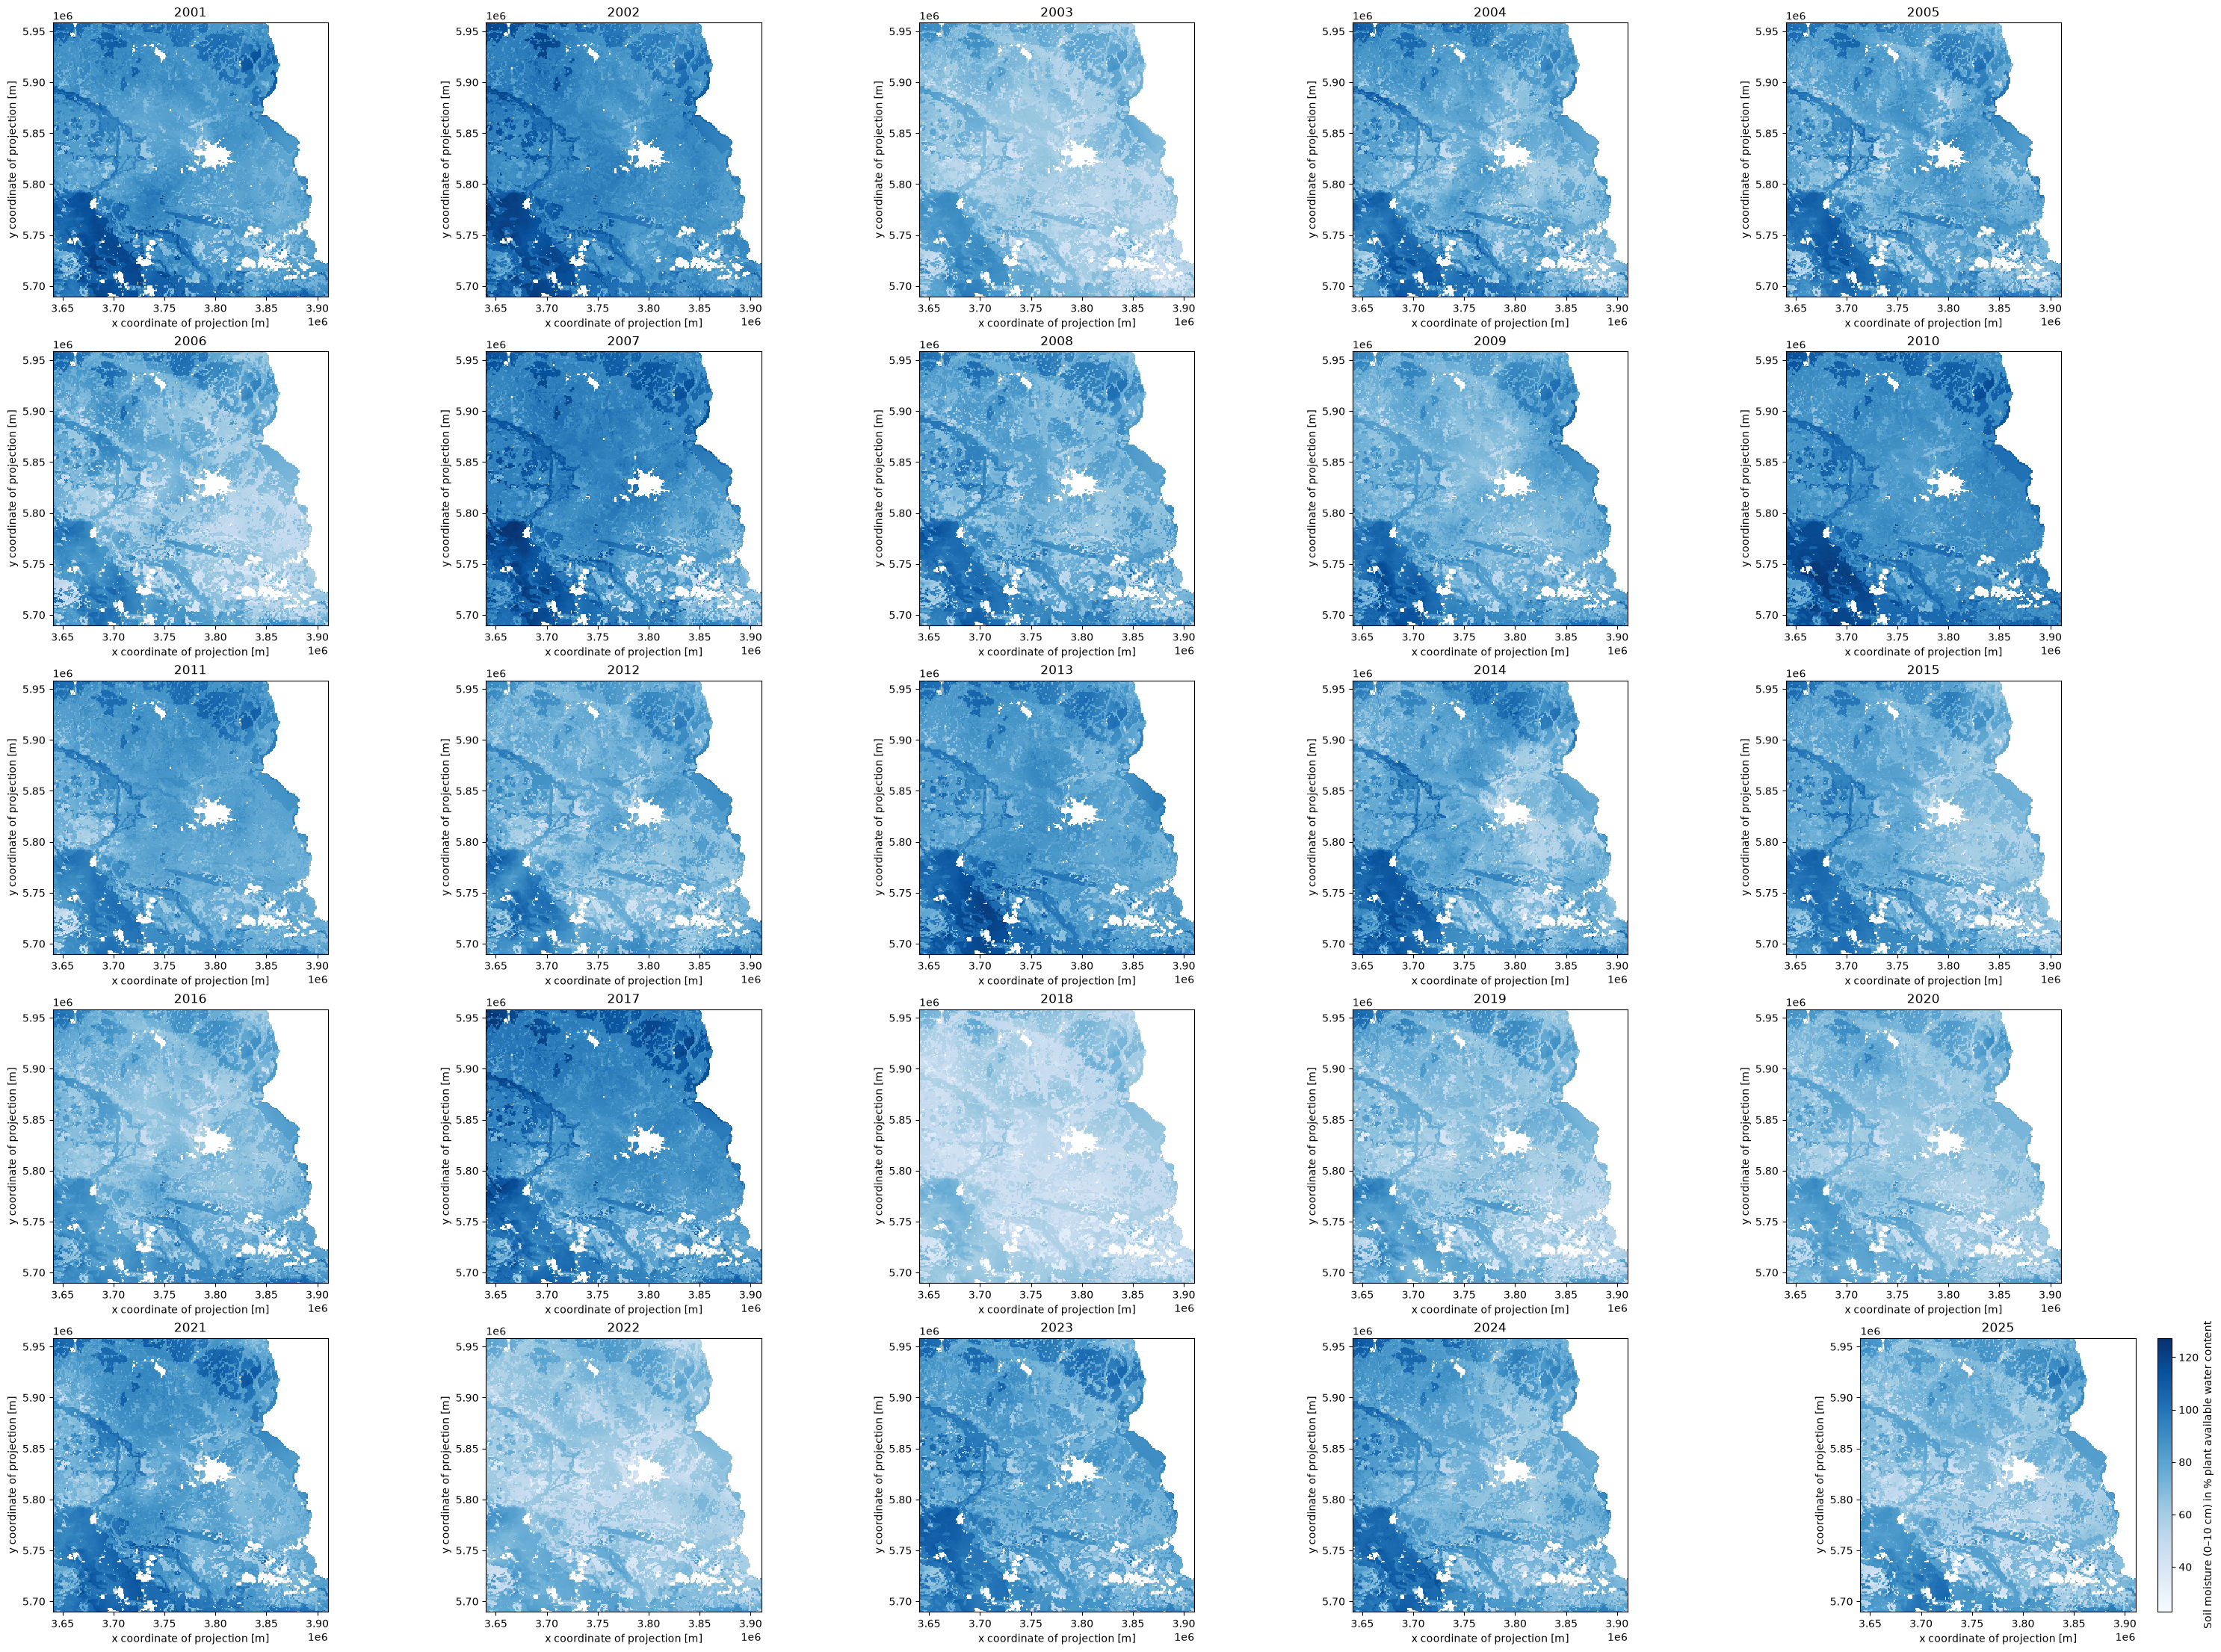

In [30]:
fig, axes = plt.subplots(
    5, 5,
    figsize=(30, 22),
    constrained_layout=True
)

axes = axes.ravel()

for i, year in enumerate(range(2001, 2026)):
    
    sm_top_year = sm_top_annual.sel(year=year)
    
    sm_top_year.plot(
        ax=axes[i],
        vmin=sm_top_min,
        vmax=sm_top_max,
        cmap="Blues",
        add_colorbar=(i == 24),
        cbar_kwargs={
            "label": "Soil moisture (0–10 cm) in % plant available water content"
        } if i == 24 else None
    )
    
    naturraum_3035.boundary.plot(
        ax=axes[i],
        color="black",
        linewidth=0.8
    )
    
    berlin_3035.plot(
        ax=axes[i],
        facecolor="white"
    )
    
    axes[i].set_title(str(year))
    axes[i].set_aspect("equal")

plt.show()

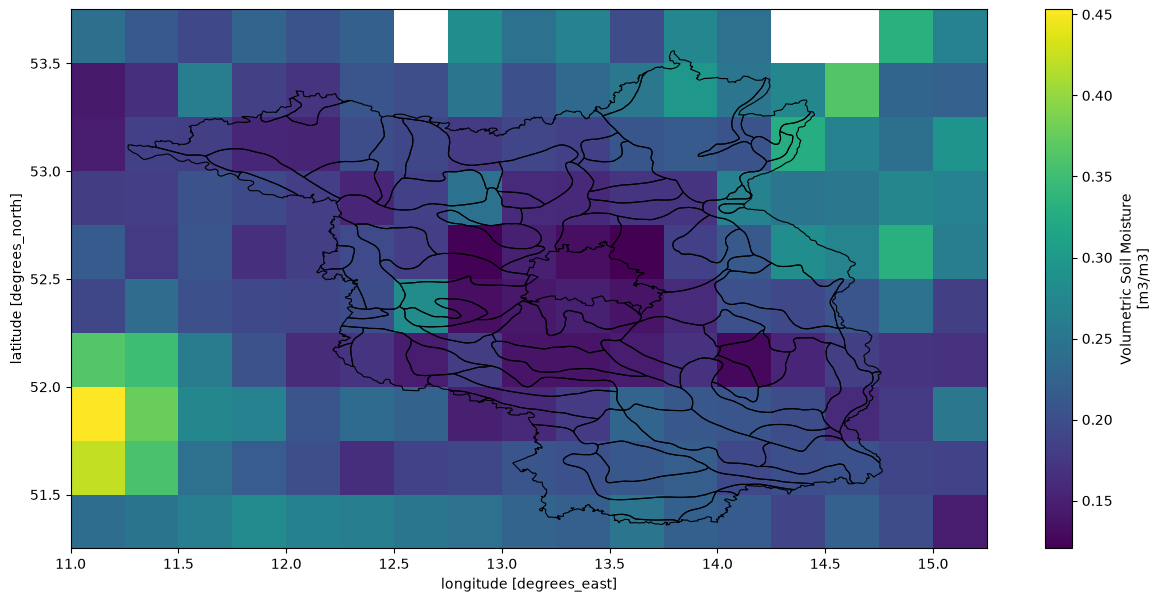

In [88]:
sm_surf_2014 = sm_surf.sel(time=slice("2014-01-01", "2014-12-31"))
sm_surf_2014_spatial_mean = sm_surf_2014.mean(dim="time")

fig, ax = plt.subplots(figsize=(15,7))

sm_surf_2014_spatial_mean["sm_copernicus"].plot(ax=ax)

NATRAUM.boundary.plot(ax=ax, color="black", linewidth=0.8)
BER_SHAPE.plot(ax=ax, facecolor="white")

ax.set_aspect("equal")

plt.show()